In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv('/content/cleaned_supermarket_sales.csv')

# Display first 5 rows
display(df.head())

# Display dataset dimensions
print("Dataset Shape:", df.shape)

print("Dataset loaded successfully!")

,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5,total,date,time,payment,cogs,gross_margin_percentage,gross_income,rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,2019-01-27,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37,Ewallet,604.17,4.761905,30.2085,5.3


Dataset Shape: (1000, 17)
Dataset loaded successfully!


In [2]:
# Dataset information
print("DATASET INFORMATION")
print("-------------------")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

DATASET INFORMATION
-------------------
Number of rows: 1000
Number of columns: 17

Column Names:
['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5', 'total', 'date', 'time', 'payment', 'cogs', 'gross_margin_percentage', 'gross_income', 'rating']

Data Types:
invoice_id                  object
branch                      object
city                        object
customer_type               object
gender                      object
product_line                object
unit_price                 float64
quantity                     int64
tax_5                      float64
total                      float64
date                        object
time                        object
payment                     object
cogs                       float64
gross_margin_percentage    float64
gross_income               float64
rating                     float64
dtype: object

Missing Values:
invoice_id                 0
branch                    

In [3]:
print("STATISTICAL SUMMARY")
display(df.describe())

print("\nTotal Revenue:", round(df["total"].sum(), 2))
print("Average Sales:", round(df["total"].mean(), 2))
print("Maximum Sale:", round(df["total"].max(), 2))
print("Minimum Sale:", round(df["total"].min(), 2))
print("Average Customer Rating:", round(df["rating"].mean(), 2))
print("Total Quantity Sold:", df["quantity"].sum())

STATISTICAL SUMMARY


,unit_price,quantity,tax_5,total,cogs,gross_margin_percentage,gross_income,rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000



Total Revenue: 322966.75
Average Sales: 322.97
Maximum Sale: 1042.65
Minimum Sale: 10.68
Average Customer Rating: 6.97
Total Quantity Sold: 5510


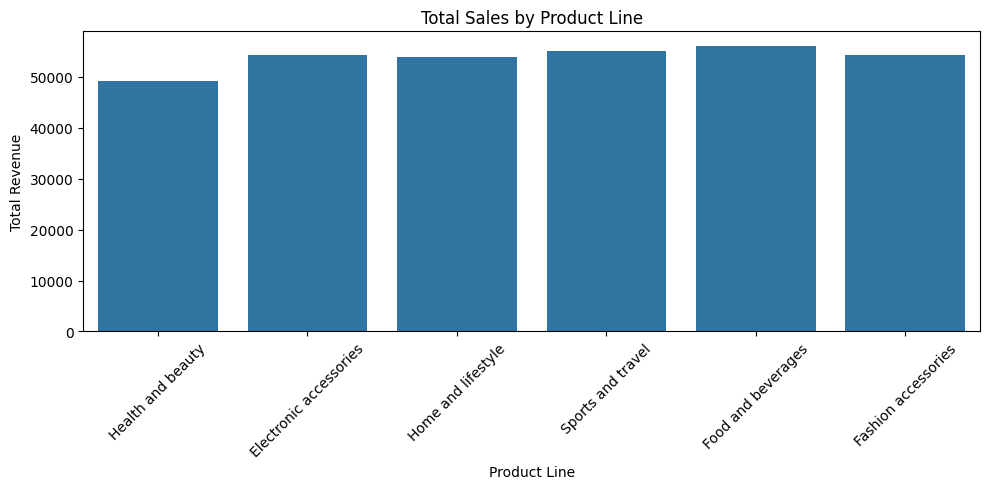

In [4]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x="product_line",
    y="total",
    estimator="sum",
    errorbar=None
)

plt.title("Total Sales by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

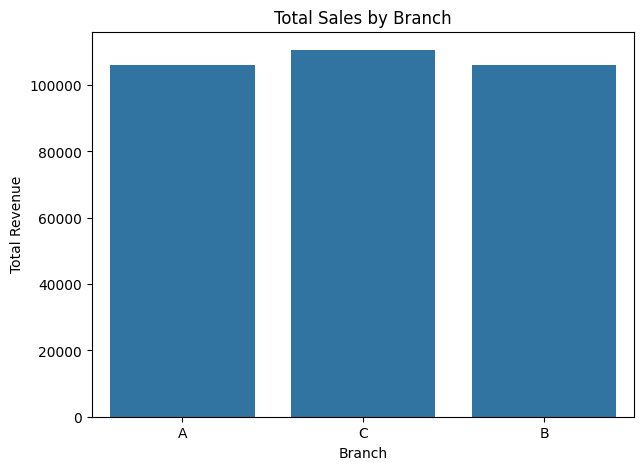

In [5]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=df,
    x="branch",
    y="total",
    estimator="sum",
    errorbar=None
)

plt.title("Total Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Revenue")
plt.show()

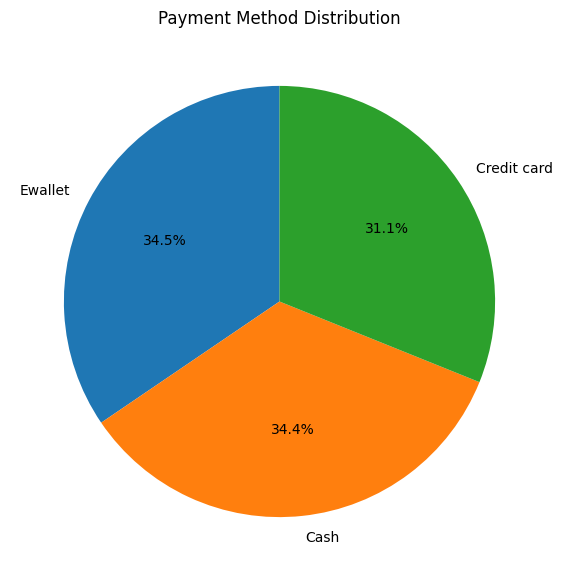

In [6]:
plt.figure(figsize=(7,7))

df["payment"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Method Distribution")
plt.ylabel("")
plt.show()

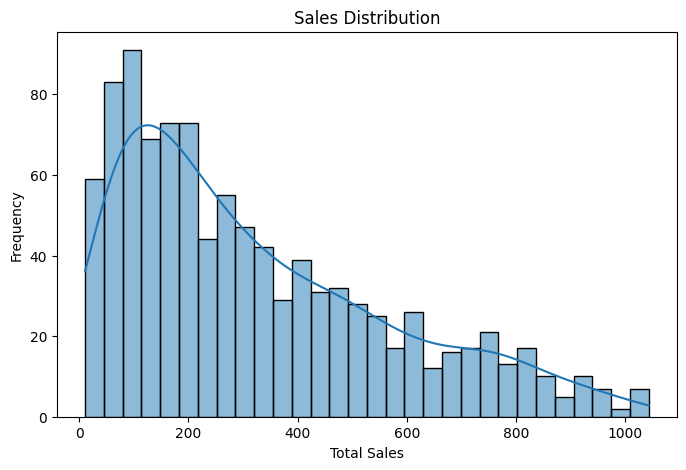

In [7]:
plt.figure(figsize=(8,5))

sns.histplot(df["total"], bins=30, kde=True)

plt.title("Sales Distribution")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")
plt.show()

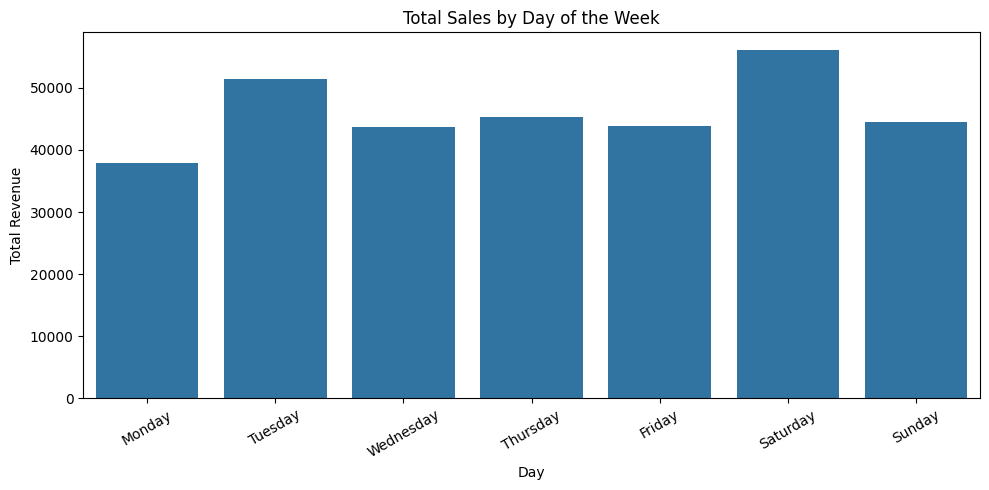

In [8]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["day"] = df["date"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x="day",
    y="total",
    order=day_order,
    estimator="sum",
    errorbar=None
)

plt.title("Total Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [9]:
# Identify outliers using IQR method

Q1 = df["total"].quantile(0.25)
Q3 = df["total"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["total"] < lower_limit) |
    (df["total"] > upper_limit)
]

print("OUTLIER ANALYSIS")
print("----------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(outliers))

display(outliers.head(10))

OUTLIER ANALYSIS
----------------
Q1: 124.422375
Q3: 471.35024999999996
IQR: 346.927875
Lower Limit: -395.9694375
Upper Limit: 991.7420625
Number of Outliers: 9


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5,total,date,time,payment,cogs,gross_margin_percentage,gross_income,rating,day
166,234-65-2137,C,Naypyitaw,Normal,Male,Home and lifestyle,95.58,10,47.790,1003.590,2019-01-16,13:32,Cash,955.8,4.761905,47.790,4.8,Wednesday
167,687-47-8271,A,Yangon,Normal,Male,Fashion accessories,98.98,10,49.490,1039.290,2019-02-08,16:20,Credit card,989.8,4.761905,49.490,8.7,Friday
350,860-79-0874,C,Naypyitaw,Member,Female,Fashion accessories,99.30,10,49.650,1042.650,2019-02-15,14:53,Credit card,993.0,4.761905,49.650,6.6,Friday
357,554-42-2417,C,Naypyitaw,Normal,Female,Sports and travel,95.44,10,47.720,1002.120,2019-01-09,13:45,Cash,954.4,4.761905,47.720,5.2,Wednesday
422,271-88-8734,C,Naypyitaw,Member,Female,Fashion accessories,97.21,10,48.605,1020.705,2019-02-08,13:00,Credit card,972.1,4.761905,48.605,8.7,Friday
557,283-26-5248,C,Naypyitaw,Member,Female,Food and beverages,98.52,10,49.260,1034.460,2019-01-30,20:23,Ewallet,985.2,4.761905,49.260,4.5,Wednesday
699,751-41-9720,C,Naypyitaw,Normal,Male,Home and lifestyle,97.50,10,48.750,1023.750,2019-01-12,16:18,Ewallet,975.0,4.761905,48.750,8.0,Saturday
792,744-16-7898,B,Mandalay,Normal,Female,Home and lifestyle,97.37,10,48.685,1022.385,2019-01-15,13:48,Credit card,973.7,4.761905,48.685,4.9,Tuesday
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.690,1022.490,2019-03-02,17:16,Ewallet,973.8,4.761905,48.690,4.4,Saturday


In [10]:
print("DETAILED BUSINESS INSIGHTS")

print("\n1. Product Line Revenue:")
display(df.groupby("product_line")["total"].sum().sort_values(ascending=False))

print("\n2. Branch Revenue:")
display(df.groupby("branch")["total"].sum().sort_values(ascending=False))

print("\n3. Payment Method Percentage:")
display(df["payment"].value_counts(normalize=True).mul(100).round(2))

print("\n4. Average Sales:")
print(round(df["total"].mean(), 2))

print("\n5. Daily Revenue:")
display(df.groupby("day")["total"].sum().sort_values(ascending=False))

DETAILED BUSINESS INSIGHTS

1. Product Line Revenue:


,total
product_line,
Food and beverages,56144.8440
Sports and travel,55122.8265
Electronic accessories,54337.5315
Fashion accessories,54305.8950
Home and lifestyle,53861.9130
Health and beauty,49193.7390



2. Branch Revenue:


,total
branch,
C,110568.7065
A,106200.3705
B,106197.6720



3. Payment Method Percentage:


,proportion
payment,
Ewallet,34.5
Cash,34.4
Credit card,31.1



4. Average Sales:
322.97

5. Daily Revenue:


,total
day,
Saturday,56120.8095
Tuesday,51482.2455
Thursday,45349.2480
Sunday,44457.8925
Friday,43926.3405
Wednesday,43731.1350
Monday,37899.0780


In [11]:
import json

branch_sales = df.groupby("branch")["total"].sum()
product_sales = df.groupby("product_line")["total"].sum()
payment_percent = df["payment"].value_counts(normalize=True) * 100
daily_sales = df.groupby("day")["total"].sum()

eda_report = {
    "Project": "SWYNEX Task 2 - Exploratory Data Analysis",
    "Dataset": "Supermarket Sales",
    "Total Records": int(len(df)),
    "Total Columns": int(len(df.columns)),
    "Total Revenue": round(float(df["total"].sum()), 2),
    "Average Sales": round(float(df["total"].mean()), 2),
    "Maximum Sales": round(float(df["total"].max()), 2),
    "Minimum Sales": round(float(df["total"].min()), 2),
    "Average Rating": round(float(df["rating"].mean()), 2),
    "Total Quantity": int(df["quantity"].sum()),
    "Outliers Detected": int(len(outliers)),
    "Top Product Line": str(product_sales.idxmax()),
    "Top Branch": str(branch_sales.idxmax()),
    "Most Used Payment": str(payment_percent.idxmax()),
    "Highest Sales Day": str(daily_sales.idxmax())
}

with open("eda_summary.json", "w") as file:
    json.dump(eda_report, file, indent=4)

print("EDA report generated successfully!")
print(json.dumps(eda_report, indent=4))

EDA report generated successfully!
{
    "Project": "SWYNEX Task 2 - Exploratory Data Analysis",
    "Dataset": "Supermarket Sales",
    "Total Records": 1000,
    "Total Columns": 18,
    "Total Revenue": 322966.75,
    "Average Sales": 322.97,
    "Maximum Sales": 1042.65,
    "Minimum Sales": 10.68,
    "Average Rating": 6.97,
    "Total Quantity": 5510,
    "Outliers Detected": 9,
    "Top Product Line": "Food and beverages",
    "Top Branch": "C",
    "Most Used Payment": "Ewallet",
    "Highest Sales Day": "Saturday"
}


In [12]:
from google.colab import files

df.to_csv("eda_analyzed_dataset.csv", index=False)

files.download("eda_summary.json")
files.download("eda_analyzed_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

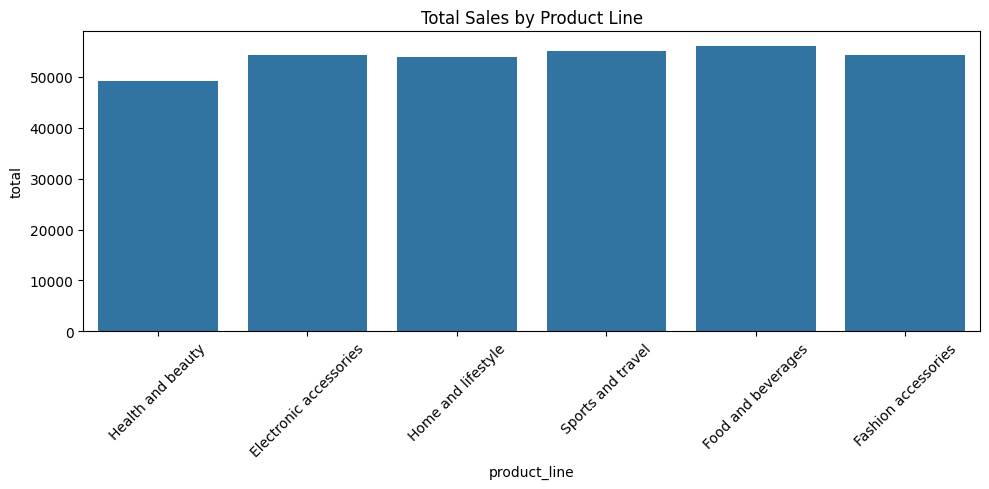

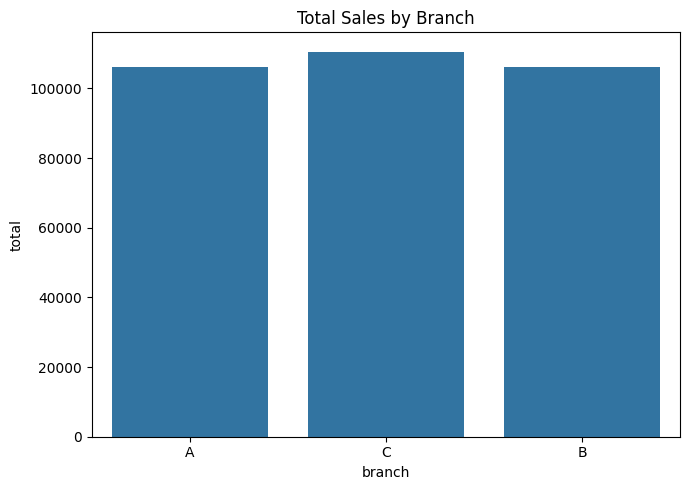

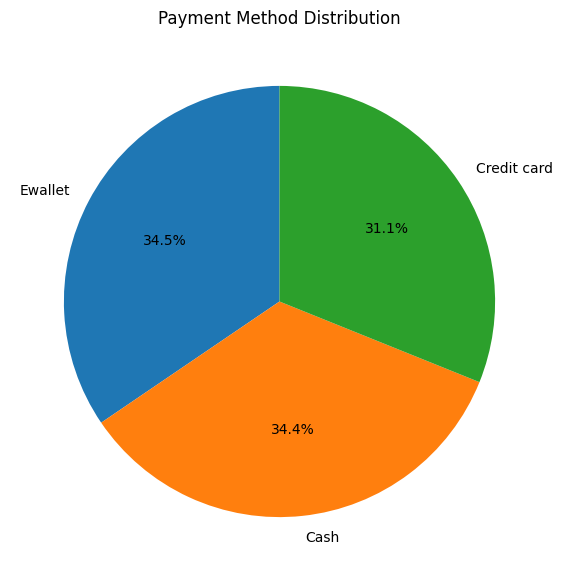

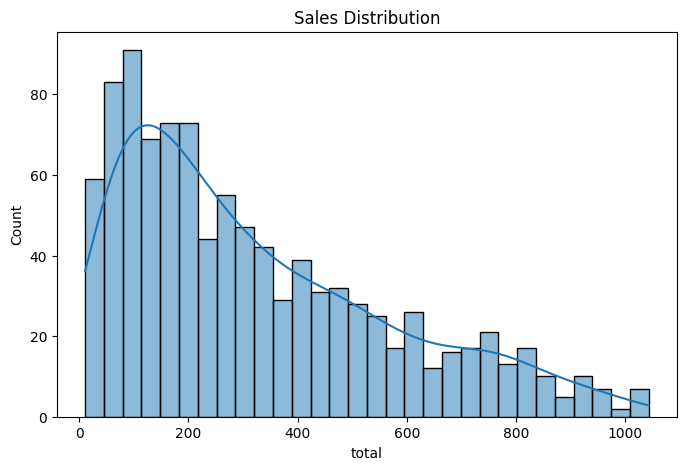

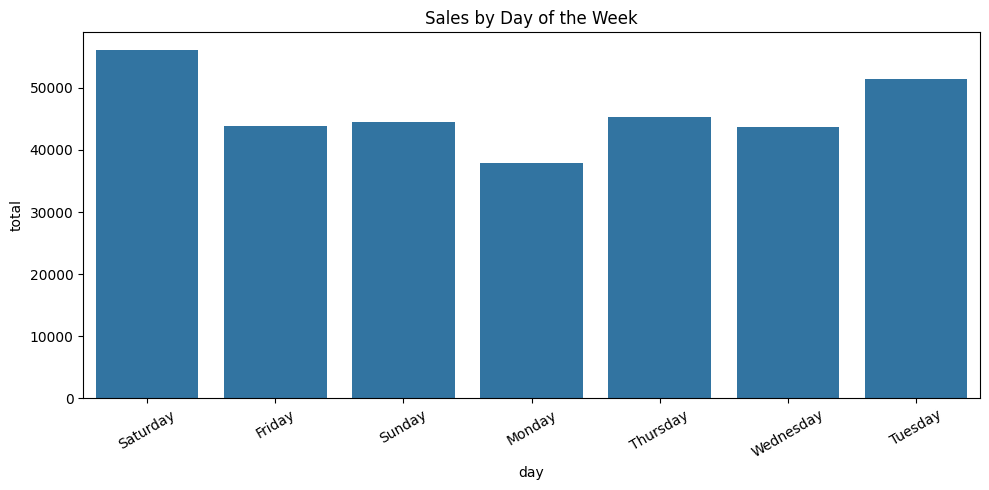

All five charts saved successfully!


In [13]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("charts", exist_ok=True)

# 1. Sales by Product Line
plt.figure(figsize=(10,5))
sns.barplot(data=df, x="product_line", y="total",
            estimator="sum", errorbar=None)
plt.title("Total Sales by Product Line")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/1_product_line_sales.png", dpi=300)
plt.show()
plt.close()

# 2. Sales by Branch
plt.figure(figsize=(7,5))
sns.barplot(data=df, x="branch", y="total",
            estimator="sum", errorbar=None)
plt.title("Total Sales by Branch")
plt.tight_layout()
plt.savefig("charts/2_branch_sales.png", dpi=300)
plt.show()
plt.close()

# 3. Payment Method Distribution
plt.figure(figsize=(7,7))
df["payment"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Payment Method Distribution")
plt.ylabel("")
plt.savefig("charts/3_payment_distribution.png", dpi=300)
plt.show()
plt.close()

# 4. Sales Distribution
plt.figure(figsize=(8,5))
sns.histplot(df["total"], bins=30, kde=True)
plt.title("Sales Distribution")
plt.savefig("charts/4_sales_distribution.png", dpi=300)
plt.show()
plt.close()

# 5. Sales by Day
plt.figure(figsize=(10,5))
sns.barplot(data=df, x="day", y="total",
            estimator="sum", errorbar=None)
plt.title("Sales by Day of the Week")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("charts/5_daily_sales.png", dpi=300)
plt.show()
plt.close()

print("All five charts saved successfully!")

In [19]:
import shutil
from google.colab import files

shutil.make_archive("task2_charts", "zip", "charts")

files.download("task2_charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/cleaned_supermarket_sales.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (1000, 17)


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5,total,date,time,payment,cogs,gross_margin_percentage,gross_income,rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,2019-01-27,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [18]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Column Names:
['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5', 'total', 'date', 'time', 'payment', 'cogs', 'gross_margin_percentage', 'gross_income', 'rating']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   invoice_id               1000 non-null   object 
 1   branch                   1000 non-null   object 
 2   city                     1000 non-null   object 
 3   customer_type            1000 non-null   object 
 4   gender                   1000 non-null   object 
 5   product_line             1000 non-null   object 
 6   unit_price               1000 non-null   float64
 7   quantity                 1000 non-null   int64  
 8   tax_5                    1000 non-null   float64
 9   total                    1000 non-null   float64
 1